In [4]:
import pandas as pd

weather = pd.read_csv(
    "../data/raw/dallas_weather_2025.csv",
    skiprows=3
)

print(weather.shape)
print(weather.head())
print(weather.columns.tolist())

(8760, 4)
               time  temperature_2m (°C)  relative_humidity_2m (%)  \
0  2025-01-01T00:00                 10.2                        60   
1  2025-01-01T01:00                 10.0                        62   
2  2025-01-01T02:00                  8.4                        69   
3  2025-01-01T03:00                  7.6                        72   
4  2025-01-01T04:00                  7.3                        74   

   apparent_temperature (°C)  
0                        7.3  
1                        7.2  
2                        5.6  
3                        4.8  
4                        4.4  
['time', 'temperature_2m (°C)', 'relative_humidity_2m (%)', 'apparent_temperature (°C)']


In [6]:
print("Missing values:")
print(weather.isnull().sum())

print("\nDuplicate timestamps:")
print(weather["time"].duplicated().sum())

print("\nTemperature statistics:")
print(weather["temperature_2m (°C)"].describe())

Missing values:
time                         0
temperature_2m (°C)          0
relative_humidity_2m (%)     0
apparent_temperature (°C)    0
dtype: int64

Duplicate timestamps:
0

Temperature statistics:
count    8760.000000
mean       20.220434
std         9.452431
min       -10.800000
25%        14.300000
50%        22.100000
75%        27.200000
max        39.100000
Name: temperature_2m (°C), dtype: float64


In [7]:
weather["hour_utc"] = pd.to_datetime(
    weather["time"],
    format="%Y-%m-%dT%H:%M",
    utc=True
)

print(weather[["time", "hour_utc"]].head())
print(weather["hour_utc"].dtype)

               time                  hour_utc
0  2025-01-01T00:00 2025-01-01 00:00:00+00:00
1  2025-01-01T01:00 2025-01-01 01:00:00+00:00
2  2025-01-01T02:00 2025-01-01 02:00:00+00:00
3  2025-01-01T03:00 2025-01-01 03:00:00+00:00
4  2025-01-01T04:00 2025-01-01 04:00:00+00:00
datetime64[us, UTC]


In [8]:
weather_clean = weather.rename(columns={
    "temperature_2m (°C)": "temperature_c",
    "relative_humidity_2m (%)": "humidity_pct",
    "apparent_temperature (°C)": "feels_like_c"
})

weather_clean["city"] = "Dallas"

print(weather_clean.head())
print(weather_clean.columns.tolist())

               time  temperature_c  humidity_pct  feels_like_c  \
0  2025-01-01T00:00           10.2            60           7.3   
1  2025-01-01T01:00           10.0            62           7.2   
2  2025-01-01T02:00            8.4            69           5.6   
3  2025-01-01T03:00            7.6            72           4.8   
4  2025-01-01T04:00            7.3            74           4.4   

                   hour_utc    city  
0 2025-01-01 00:00:00+00:00  Dallas  
1 2025-01-01 01:00:00+00:00  Dallas  
2 2025-01-01 02:00:00+00:00  Dallas  
3 2025-01-01 03:00:00+00:00  Dallas  
4 2025-01-01 04:00:00+00:00  Dallas  
['time', 'temperature_c', 'humidity_pct', 'feels_like_c', 'hour_utc', 'city']


In [9]:
from pathlib import Path

print("Total records:", len(weather_clean))
print("Duplicate UTC timestamps:",
      weather_clean["hour_utc"].duplicated().sum())

print("Missing values:")
print(weather_clean.isnull().sum())

output_dir = Path("../data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

weather_clean.to_csv(
    output_dir / "dallas_weather_clean_2025.csv",
    index=False
)

print("Dallas weather CSV exported!")

Total records: 8760
Duplicate UTC timestamps: 0
Missing values:
time             0
temperature_c    0
humidity_pct     0
feels_like_c     0
hour_utc         0
city             0
dtype: int64
Dallas weather CSV exported!


In [10]:
electricity = pd.read_csv(
    "../data/processed/ercot_statewide_2025.csv"
)

electricity["hour_ending_utc"] = pd.to_datetime(
    electricity["hour_ending_utc"],
    utc=True
)

print(electricity.shape)
print(electricity.head(3))

(8760, 6)
            hour_ending_utc        date  month day_of_week  hour     demand_mw
0 2025-01-01 07:00:00+00:00  2025-01-01      1   Wednesday     1  43223.859905
1 2025-01-01 08:00:00+00:00  2025-01-01      1   Wednesday     2  43122.532212
2 2025-01-01 09:00:00+00:00  2025-01-01      1   Wednesday     3  42918.511847


In [11]:
electricity["weather_hour_utc"] = (
    electricity["hour_ending_utc"] - pd.Timedelta(hours=1)
)

combined = electricity.merge(
    weather_clean[
        ["hour_utc", "temperature_c",
         "humidity_pct", "feels_like_c"]
    ],
    left_on="weather_hour_utc",
    right_on="hour_utc",
    how="left",
    validate="one_to_one"
)

print("Combined shape:", combined.shape)
print(combined.head(3))

Combined shape: (8760, 11)
            hour_ending_utc        date  month day_of_week  hour  \
0 2025-01-01 07:00:00+00:00  2025-01-01      1   Wednesday     1   
1 2025-01-01 08:00:00+00:00  2025-01-01      1   Wednesday     2   
2 2025-01-01 09:00:00+00:00  2025-01-01      1   Wednesday     3   

      demand_mw          weather_hour_utc                  hour_utc  \
0  43223.859905 2025-01-01 06:00:00+00:00 2025-01-01 06:00:00+00:00   
1  43122.532212 2025-01-01 07:00:00+00:00 2025-01-01 07:00:00+00:00   
2  42918.511847 2025-01-01 08:00:00+00:00 2025-01-01 08:00:00+00:00   

   temperature_c  humidity_pct  feels_like_c  
0            6.5          76.0           3.1  
1            6.2          75.0           2.6  
2            5.0          77.0           1.2  


In [12]:
print("Total electricity rows:", len(electricity))

print("Matched weather rows:",
      combined["temperature_c"].notna().sum())

print("Unmatched weather rows:",
      combined["temperature_c"].isna().sum())

print("\nFirst electricity timestamp:",
      combined["hour_ending_utc"].min())

print("Last electricity timestamp:",
      combined["hour_ending_utc"].max())

print("\nCorrelation with Dallas temperature:")
print(
    combined[["demand_mw", "temperature_c"]]
    .corr()
)

Total electricity rows: 8760
Matched weather rows: 8754
Unmatched weather rows: 6

First electricity timestamp: 2025-01-01 07:00:00+00:00
Last electricity timestamp: 2026-01-01 06:00:00+00:00

Correlation with Dallas temperature:
               demand_mw  temperature_c
demand_mw       1.000000       0.514921
temperature_c   0.514921       1.000000


In [13]:
unmatched = combined[
    combined["temperature_c"].isna()
]

print(unmatched[
    ["hour_ending_utc", "weather_hour_utc", "demand_mw"]
])

               hour_ending_utc          weather_hour_utc     demand_mw
8754 2026-01-01 01:00:00+00:00 2026-01-01 00:00:00+00:00  50888.149238
8755 2026-01-01 02:00:00+00:00 2026-01-01 01:00:00+00:00  49868.701664
8756 2026-01-01 03:00:00+00:00 2026-01-01 02:00:00+00:00  49069.809445
8757 2026-01-01 04:00:00+00:00 2026-01-01 03:00:00+00:00  48256.977350
8758 2026-01-01 05:00:00+00:00 2026-01-01 04:00:00+00:00  47394.684164
8759 2026-01-01 06:00:00+00:00 2026-01-01 05:00:00+00:00  46810.796215


In [14]:
analysis = combined.dropna(
    subset=["temperature_c"]
).copy()

analysis["temp_range"] = pd.cut(
    analysis["temperature_c"],
    bins=[-20, 0, 10, 20, 30, 45],
    labels=["Below 0", "0–10", "10–20", "20–30", "30–45"]
)

print(
    analysis.groupby(
        "temp_range", observed=True
    )["demand_mw"].agg(
        ["count", "mean", "max"]
    ).round(2)
)

            count      mean       max
temp_range                           
Below 0       273  64494.37  80524.70
0–10         1197  51355.41  71428.92
10–20        2182  46698.92  61632.39
20–30        3899  55964.01  77052.88
30–45        1203  73783.19  83679.00


Matplotlib is building the font cache; this may take a moment.


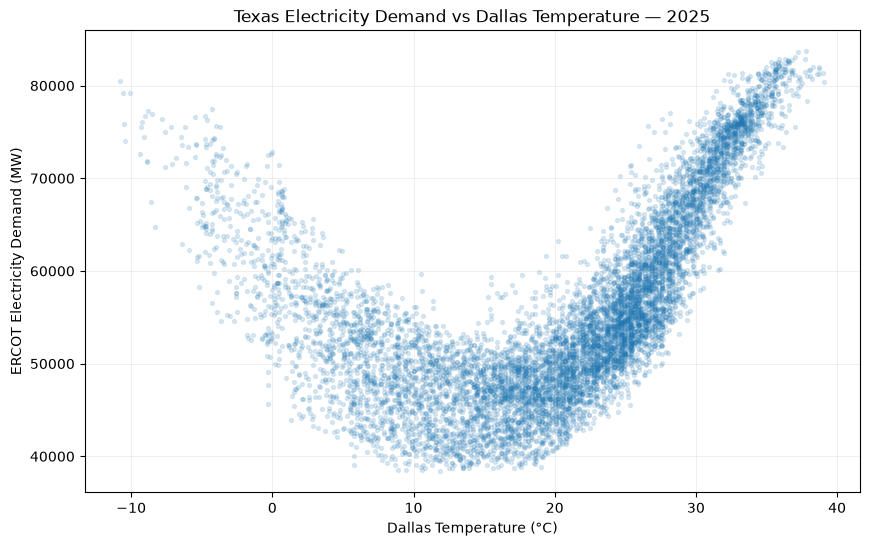

In [16]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.scatter(
    analysis["temperature_c"],
    analysis["demand_mw"],
    alpha=0.15,
    s=8
)

plt.title("Texas Electricity Demand vs Dallas Temperature — 2025")
plt.xlabel("Dallas Temperature (°C)")
plt.ylabel("ERCOT Electricity Demand (MW)")
plt.grid(alpha=0.2)
plt.show()

In [17]:
temp_summary = (
    analysis.groupby("temp_range", observed=True)["demand_mw"]
    .agg(["count", "mean", "max"])
    .round(2)
)

print(temp_summary)

            count      mean       max
temp_range                           
Below 0       273  64494.37  80524.70
0–10         1197  51355.41  71428.92
10–20        2182  46698.92  61632.39
20–30        3899  55964.01  77052.88
30–45        1203  73783.19  83679.00


In [18]:

analysis["weather_condition"] = pd.cut(
    analysis["temperature_c"],
    bins=[-20, 10, 25, 45],
    labels=["Cold", "Mild", "Hot"]
)

condition_summary = (
    analysis.groupby("weather_condition", observed=True)["demand_mw"]
    .agg(["count", "mean", "max"])
    .round(2)
)

print(condition_summary)

                   count      mean       max
weather_condition                           
Cold                1470  53795.50  80524.70
Mild                4112  49045.75  70246.18
Hot                 3172  65317.08  83679.00


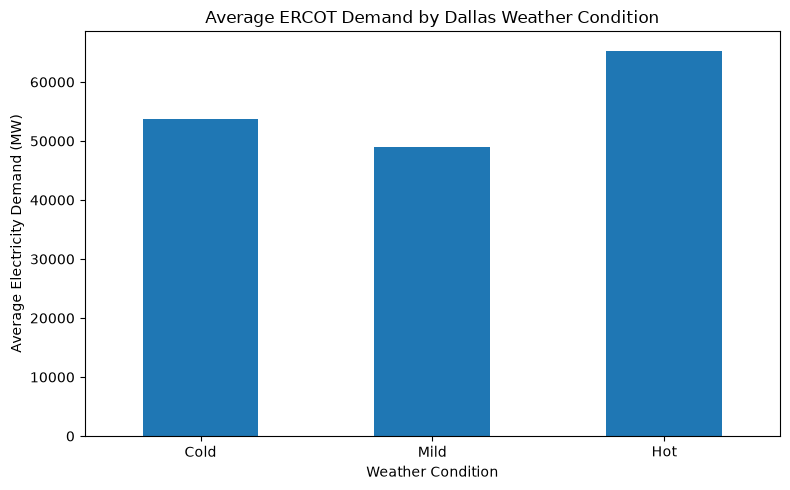

In [19]:
condition_summary["mean"].plot(
    kind="bar",
    figsize=(8, 5),
    title="Average ERCOT Demand by Dallas Weather Condition"
)

plt.xlabel("Weather Condition")
plt.ylabel("Average Electricity Demand (MW)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()